In [1]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt
#import matplotlib.dates as mdates

In [2]:
# Load

df = pd.read_csv("data/weather.csv", parse_dates = ["time"], usecols = ["time", "temperature_2m", "relative_humidity_2m"])
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2026-08-01", "2026-09-01", inclusive="left")]

df.head()

,time,temperature_2m,relative_humidity_2m
233015,2026-08-01 00:00:00-06:00,17.8,58.0
233016,2026-08-01 01:00:00-06:00,16.9,61.0
233017,2026-08-01 02:00:00-06:00,15.5,65.0
233018,2026-08-01 03:00:00-06:00,14.6,69.0
233019,2026-08-01 04:00:00-06:00,14.0,69.0


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df[["temperature_2m", "relative_humidity_2m"]].describe().T)

2026-08-01 00:00:00-06:00 to 2026-08-31 23:00:00-06:00 

Shape: (744, 3) 

Dtypes:
time                    datetime64[us, America/Edmonton]
temperature_2m                                   float64
relative_humidity_2m                             float64
dtype: object 

Any Nulls: True 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False 



,count,mean,std,min,25%,50%,75%,max
temperature_2m,744.0,16.600134,5.634762,5.4,12.3,15.1,21.1,34.1
relative_humidity_2m,718.0,64.324513,22.560669,15.0,44.0,68.0,83.0,100.0


In [4]:
# Additional Inspect
# Any Nulls = True

nulls = pd.DataFrame({"count": df.isna().sum(),
                            "pct": df.isna().mean().mul(100).round(2).astype(str).add("%")
                            })

nulls

,count,pct
time,0,0.0%
temperature_2m,0,0.0%
relative_humidity_2m,26,3.49%


In [5]:
# Missing Intervals

missing_df = df.loc[df["relative_humidity_2m"].isna(), ["time"]].copy()

missing_df["run"] = missing_df["time"].diff().gt(pd.Timedelta(hours = 1)).cumsum()

missing = (missing_df.groupby("run")
                          .agg(start=("time", "min"), 
                               end=("time", "max"), 
                               hours=("time", "size"))
                          .reset_index(drop=True))

missing

,start,end,hours
0,2026-08-05 10:00:00-06:00,2026-08-05 15:00:00-06:00,6
1,2026-08-08 11:00:00-06:00,2026-08-08 11:00:00-06:00,1
2,2026-08-11 13:00:00-06:00,2026-08-11 13:00:00-06:00,1
3,2026-08-13 16:00:00-06:00,2026-08-13 16:00:00-06:00,1
4,2026-08-14 07:00:00-06:00,2026-08-14 07:00:00-06:00,1
5,2026-08-15 08:00:00-06:00,2026-08-15 14:00:00-06:00,7
6,2026-08-20 15:00:00-06:00,2026-08-20 20:00:00-06:00,6
7,2026-08-21 03:00:00-06:00,2026-08-21 03:00:00-06:00,1
8,2026-08-21 13:00:00-06:00,2026-08-21 13:00:00-06:00,1
9,2026-08-22 08:00:00-06:00,2026-08-22 08:00:00-06:00,1


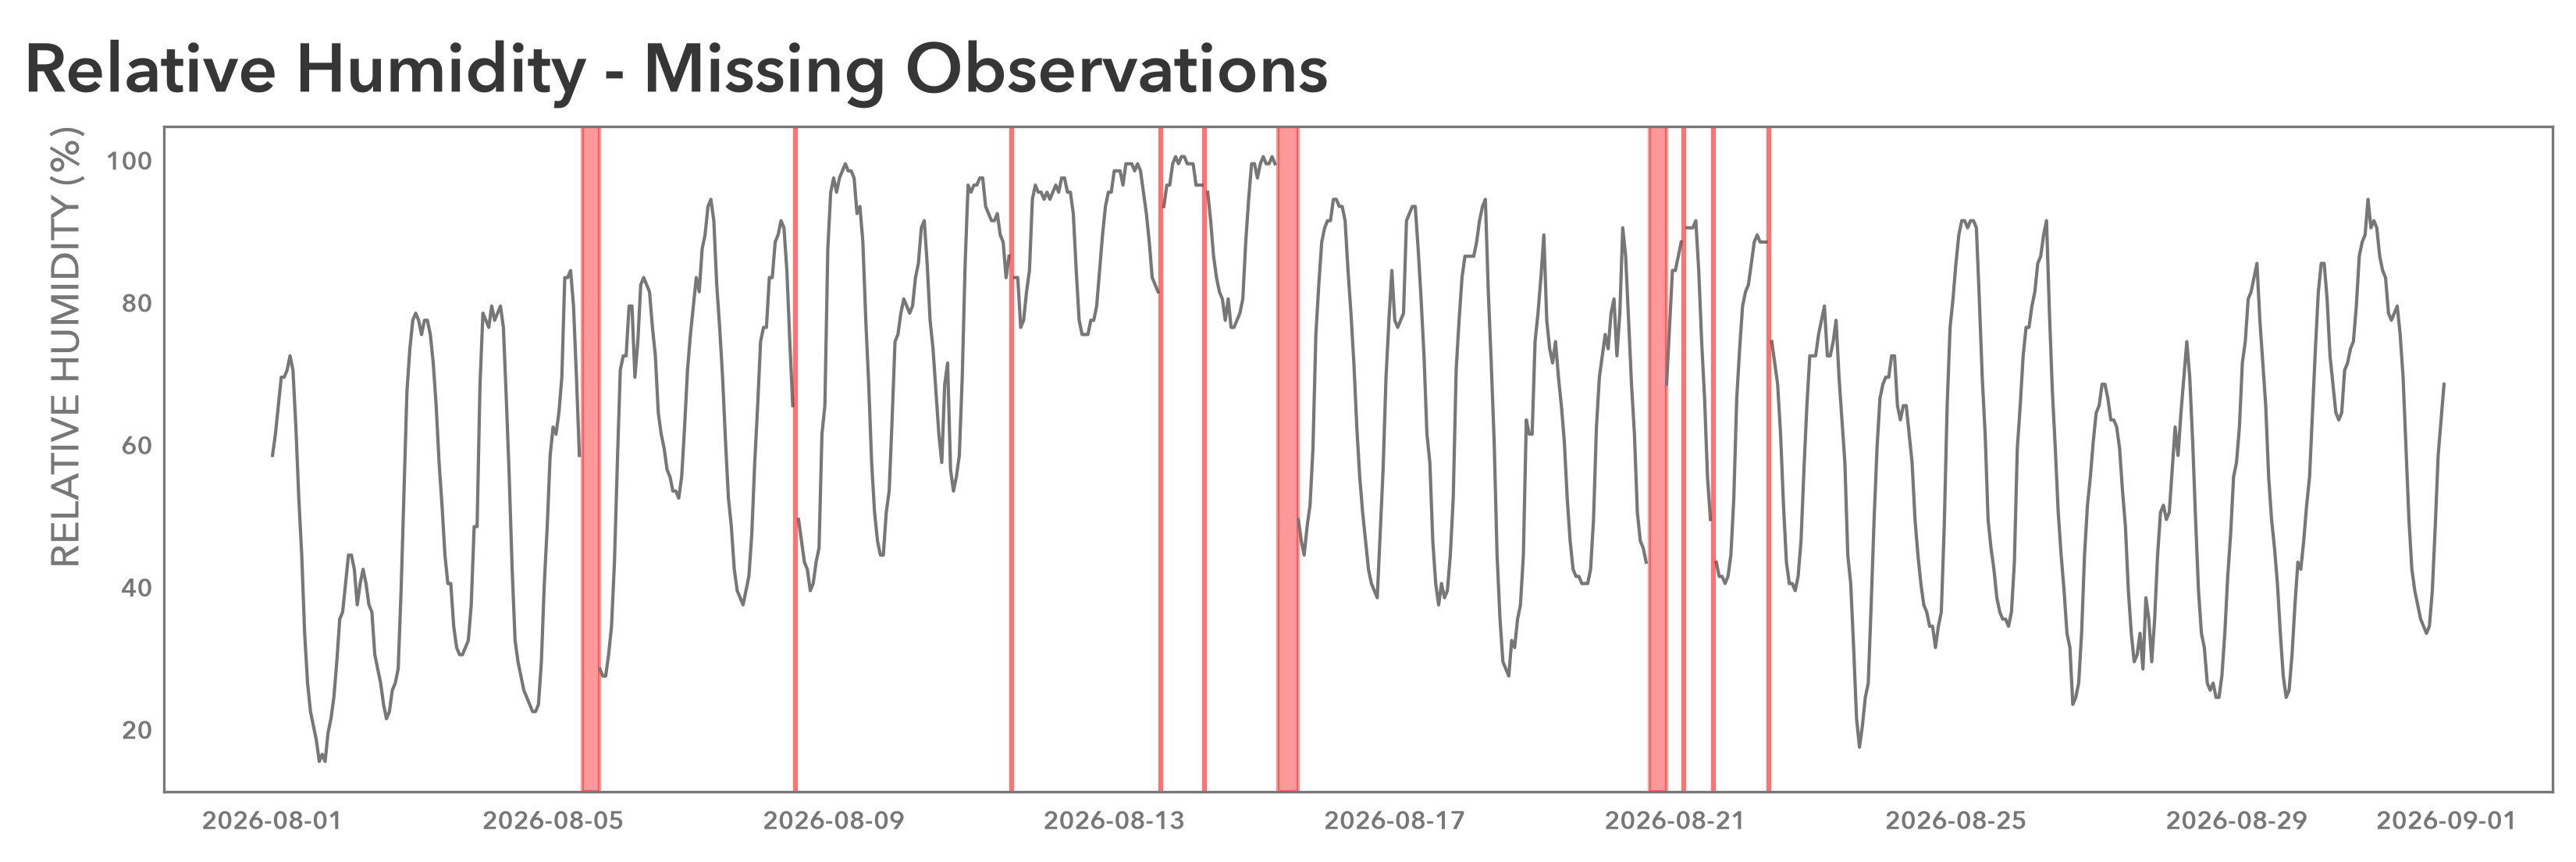

In [6]:
# Visualize Missingness

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 600

fig, ax = plt.subplots(figsize = (12, 4), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.95,
    top = 0.85,
    bottom = 0.14
)

STRUCTURE = "#777777"
TITLE = "#363636"

# Plot

ax.plot(df["time"], df["relative_humidity_2m"], color = STRUCTURE, linewidth = 1)

# Emphasis

for row in missing.itertuples():
    if row.hours == 1:
        ax.axvline(row.start, color = "red", alpha = 0.55)
    else:
        ax.axvspan(row.start, row.end + pd.Timedelta(hours = 1), color = "red", alpha = 0.4)

# Scale & Axes

ax.set_ylabel("RELATIVE HUMIDITY (%)", loc = "top", fontsize = 12, fontweight = 500, color = STRUCTURE)

# Ticks

ax.tick_params(axis = "x", labelsize = 8, length = 0, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 8, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "bottom", "left"]].set_color(STRUCTURE)

# Composition

fig.suptitle("Relative Humidity - Missing Observations", x = 0.05, y = 0.96, ha = "left", va = "top", fontsize = 21, fontweight = 600, color = TITLE)

# Output

fig.savefig("outputs/dirty.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()

In [7]:
# Clean

# Retain Days with at least 22 of 24 valid humidity observations

# We're accepting a small amount of incomplete measurement for the daily humidity average. The final output will describe
# the relationship among August 2026 days with at least 22 valid humidity observations.

humidity_hours = df.groupby(df["time"].dt.normalize())["relative_humidity_2m"].transform("count")

clean_df = df.loc[humidity_hours.ge(22)].copy()

print("Excluded Days:", df.loc[humidity_hours.lt(22), "time"].dt.date.nunique())

Excluded Days: 3


In [8]:
# Transform

output_df = (clean_df.assign(date = lambda x: x["time"].dt.date)
                    .groupby("date", as_index = False)
                    .agg(avg_temp = ("temperature_2m", "mean"),
                         avg_humidity = ("relative_humidity_2m", "mean"))
)

output_df

,date,avg_temp,avg_humidity
0,2026-08-01,23.250000,41.041667
1,2026-08-02,16.795833,37.458333
2,2026-08-03,13.700000,53.875000
3,2026-08-04,15.787500,49.375000
4,2026-08-06,15.129167,68.166667
5,2026-08-07,16.312500,65.125000
6,2026-08-08,17.591667,67.565217
7,2026-08-09,16.012500,76.291667
8,2026-08-10,16.483333,74.625000
9,2026-08-11,14.470833,89.347826


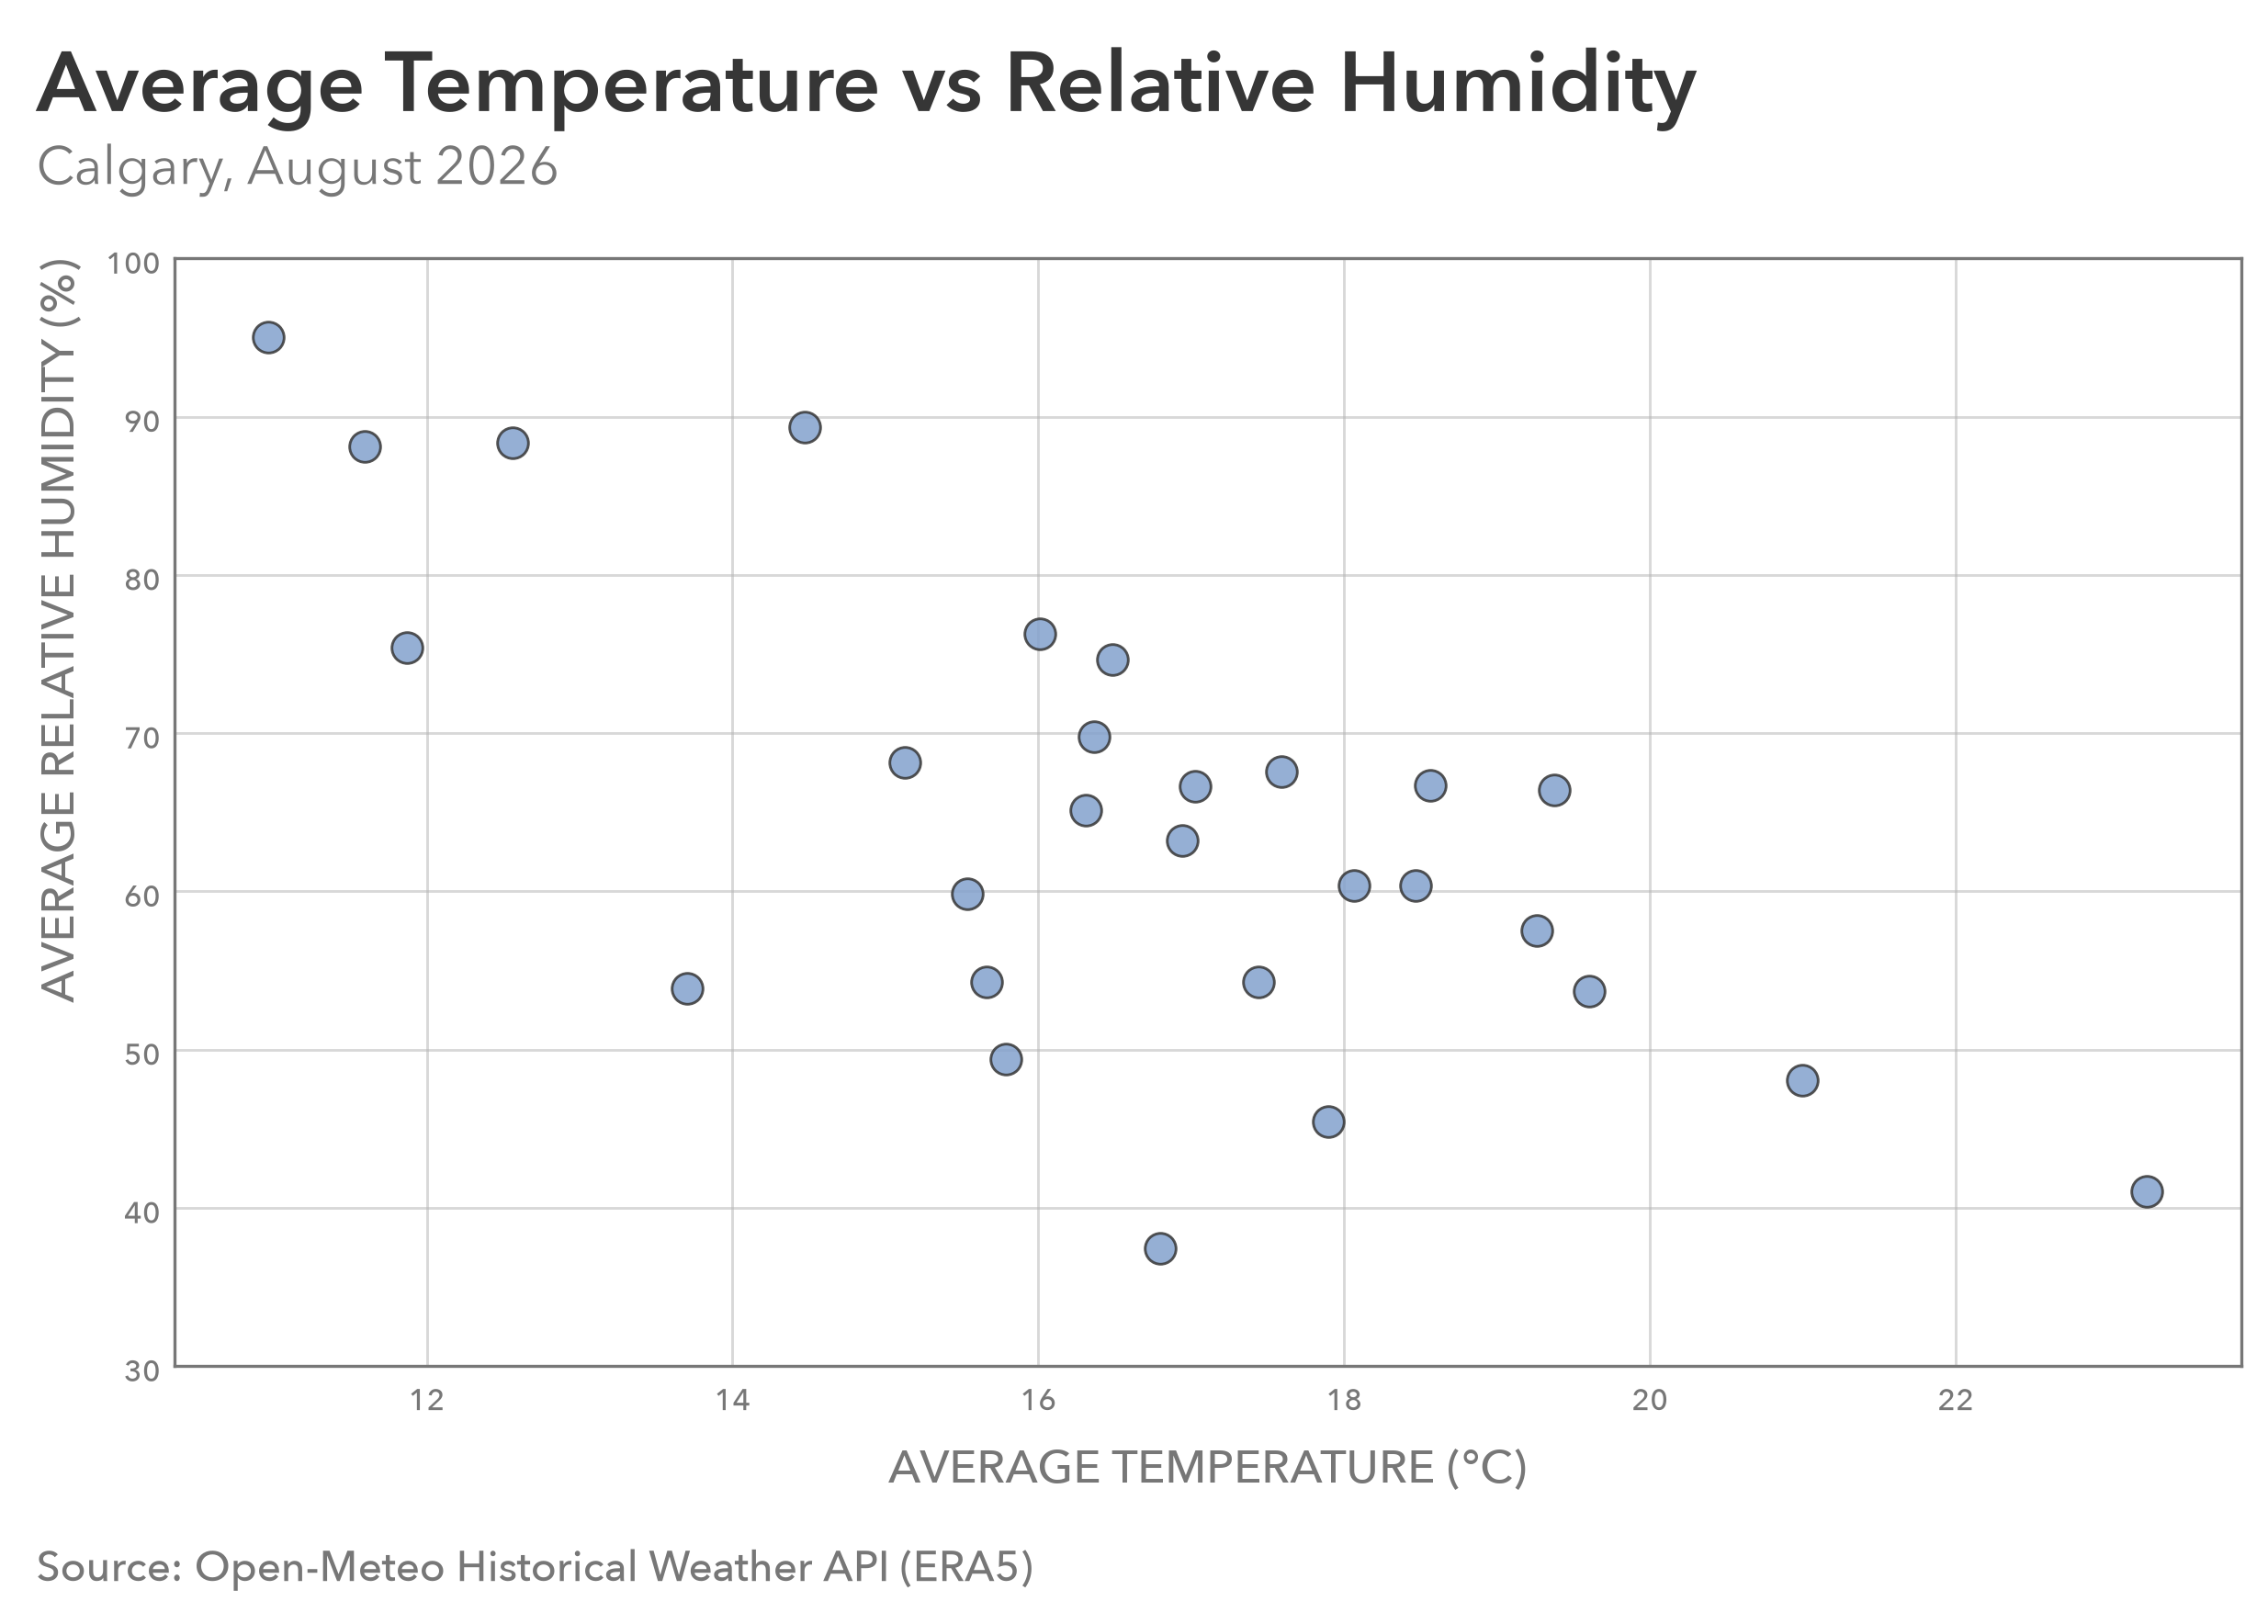

In [9]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (10, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.85,
    top = 0.80,
    bottom = 0.13
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
BLUE = "#83A1CD"
TITLE = "#363636"

# Plot

points = ax.scatter(output_df["avg_temp"], output_df["avg_humidity"], s = 65, color = BLUE, alpha = 0.85, edgecolors = TITLE, linewidths = 0.7)

# Scale & Axes

ax.set_xlabel("AVERAGE TEMPERATURE (°C)", loc = "center", fontsize = 12, fontweight = 500, color = STRUCTURE)

ax.set_ylabel("AVERAGE RELATIVE HUMIDITY (%)", loc = "top", fontsize = 12, fontweight = 500, color = STRUCTURE)

# Ticks

ax.set_yticks([30, 40, 50, 60, 70, 80, 90, 100])

ax.tick_params(axis = "x", labelsize = 8, length = 0, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 8, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "bottom", "left"]].set_color(STRUCTURE)

ax.set_axisbelow(True)
ax.grid(color = GRID, linewidth = 0.7, alpha = 0.5)

# Composition

fig.suptitle("Average Temperature vs Relative Humidity", x = 0.05, y = 0.94, ha = "left", va = "top", fontweight = 600, fontsize = 22, color = TITLE)

fig.text(0.05, 0.845, "Calgary, August 2026", fontsize = 14, fontweight = 400, color = STRUCTURE)

fig.text(0.05, 0, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 11, color = STRUCTURE)

# Output

fig.savefig("outputs/avg-temperature-vs-avg-humidity-august-2026.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()